# Multi-Label Image Classification with EfficientNet-B0

Fine-tunes an ImageNet-pretrained EfficientNet-B0 to predict 100 labels per image on Flickr8k. The labels come from the captions (see `01_caption_exploration.ipynb`). The notebook covers data loading, training, evaluation, threshold tuning and example predictions.

In [18]:
# ==========================================
# 1. Imports & Device Setup
# ==========================================
import os, re, time, torch
import pandas as pd
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from PIL import Image

device = "mps" if torch.backends.mps.is_available() else (
    "cuda" if torch.cuda.is_available() else "cpu"
)
print(f"Using device: {device}")

# ==========================================
# 2. Load Captions & Label Vocabulary
# ==========================================
df = pd.read_csv("dataset/captions.csv")
tokens = pd.read_csv("dataset/top_tokens_with_images.csv")["token"].tolist()

# Keep only the label tokens of a caption
def extract_tokens(text):
    words = re.findall(r"[a-z]+", text.lower())
    return [w for w in words if w in tokens]

df["labels"] = df["caption"].apply(extract_tokens)

# Merge the five captions of each image into one label set
df_img = df.groupby("image_id")["labels"].sum().apply(set).reset_index()

# Multi-hot encoding of the label sets
mlb = MultiLabelBinarizer(classes=tokens)
Y = mlb.fit_transform(df_img["labels"])
label_dict = dict(zip(df_img["image_id"], Y))

print(f"{len(df_img)} unique images loaded")

Using device: cpu
8091 unique images loaded


In [20]:
# ==========================================
# 3. Train / Validation / Test Split
# ==========================================
train_df, test_df = train_test_split(df_img, test_size=0.2, random_state=42)
train_df, val_df = train_test_split(train_df, test_size=0.1, random_state=42)

print(f"Split sizes -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

Split sizes -> Train: 5824, Val: 648, Test: 1619


In [35]:
# ==========================================
# 4. Dataset & DataLoader
# ==========================================
class FlickrDataset(Dataset):
    def __init__(self, image_dir, df_subset, label_dict, transform=None):
        self.image_dir = image_dir
        self.image_ids = df_subset["image_id"].tolist()
        self.label_dict = label_dict
        self.transform = transform or T.Compose([
            T.Resize((224, 224)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225])
        ])

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        img_path = os.path.join(self.image_dir, img_id)
        image = Image.open(img_path).convert("RGB")
        label = torch.tensor(self.label_dict[img_id]).float()
        return self.transform(image), label


train_dataset = FlickrDataset("dataset/Images", train_df, label_dict)
val_dataset   = FlickrDataset("dataset/Images", val_df, label_dict)
test_dataset  = FlickrDataset("dataset/Images", test_df, label_dict)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False)
print("Datasets and loaders created")

Datasets and loaders created


In [36]:
# ==========================================
# 5. Model (EfficientNet-B0)
# ==========================================
class MultiLabelEfficientNet(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        base = models.efficientnet_b0(weights="IMAGENET1K_V1")
        self.features = base.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(1280, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return torch.sigmoid(self.classifier(x))

model = MultiLabelEfficientNet(num_classes=len(tokens)).to(device)
print("Model initialized")

Model initialized


In [30]:
# ==========================================
# 6. Loss, Optimizer, Training Loop
# ==========================================
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 20

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.0
    start = time.time()

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        preds = model(imgs)
        loss = criterion(preds, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # --- Validation ---
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            preds = model(imgs)
            val_loss += criterion(preds, labels).item()

    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)
    duration = time.time() - start

    print(f"Epoch {epoch+1}/{EPOCHS} | "
          f"Train Loss: {avg_train_loss:.4f} | "
          f"Val Loss: {avg_val_loss:.4f} | "
          f"Time: {duration:.1f}s")

print("Training complete")

In [38]:
# ==========================================
# 7. Save Model
# ==========================================
torch.save(model.state_dict(), "model_multilabel_5.pth")
print("Model saved")

Model saved


In [ ]:
# ==========================================
# 8. Test Evaluation
# ==========================================
from sklearn.metrics import f1_score, precision_score, recall_score
import numpy as np

model.eval()
test_loss = 0.0
all_preds_raw, all_labels = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        preds = model(imgs)
        test_loss += criterion(preds, labels).item()
        all_preds_raw.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

avg_test_loss = test_loss / len(test_loader)
all_preds_raw = np.array(all_preds_raw)
all_labels = np.array(all_labels)

# Baseline with the default threshold of 0.5
threshold = 0.5
preds_bin = (all_preds_raw > threshold).astype(int)

f1 = f1_score(all_labels, preds_bin, average="micro")
precision = precision_score(all_labels, preds_bin, average="micro")
recall = recall_score(all_labels, preds_bin, average="micro")

print("=====================================")
print("Test Results (Threshold = 0.5)")
print(f"Loss:       {avg_test_loss:.4f}")
print(f"Precision:  {precision:.4f}")
print(f"Recall:     {recall:.4f}")
print(f"F1-Score:   {f1:.4f}")
print("=====================================")

Test Results (Threshold = 0.5)
Loss:       0.2334
Precision:  0.5380
Recall:     0.3627
F1-Score:   0.4333


In [ ]:
# ==========================================
# 9. Threshold Optimization
# ==========================================
thresholds = np.arange(0.05, 0.9, 0.05)
best_f1, best_t = 0, None
results = []

for t in thresholds:
    preds_bin = (all_preds_raw > t).astype(int)
    f1 = f1_score(all_labels, preds_bin, average="micro")
    precision = precision_score(all_labels, preds_bin, average="micro")
    recall = recall_score(all_labels, preds_bin, average="micro")
    results.append((t, precision, recall, f1))
    if f1 > best_f1:
        best_f1, best_t = f1, t

print("=====================================")
print("Threshold optimization finished")
print(f"Best threshold: {best_t:.2f}")
print(f"F1-Score:       {best_f1:.4f}")
print("=====================================")

# Metrics per threshold
df_results = pd.DataFrame(results, columns=["Threshold", "Precision", "Recall", "F1"])
display(df_results)

Threshold optimization finished
Best threshold: 0.25
F1-Score:       0.4572


,Threshold,Precision,Recall,F1
0,0.05,0.234754,0.775855,0.360446
1,0.10,0.294400,0.675043,0.409994
2,0.15,0.340749,0.611167,0.437549
3,0.20,0.379143,0.560834,0.452429
4,0.25,0.409950,0.516802,0.457216
5,0.30,0.437716,0.476897,0.456467
6,0.35,0.463863,0.445756,0.454629
7,0.40,0.490003,0.417077,0.450608
8,0.45,0.514812,0.388905,0.443088
9,0.50,0.538032,0.362688,0.433293


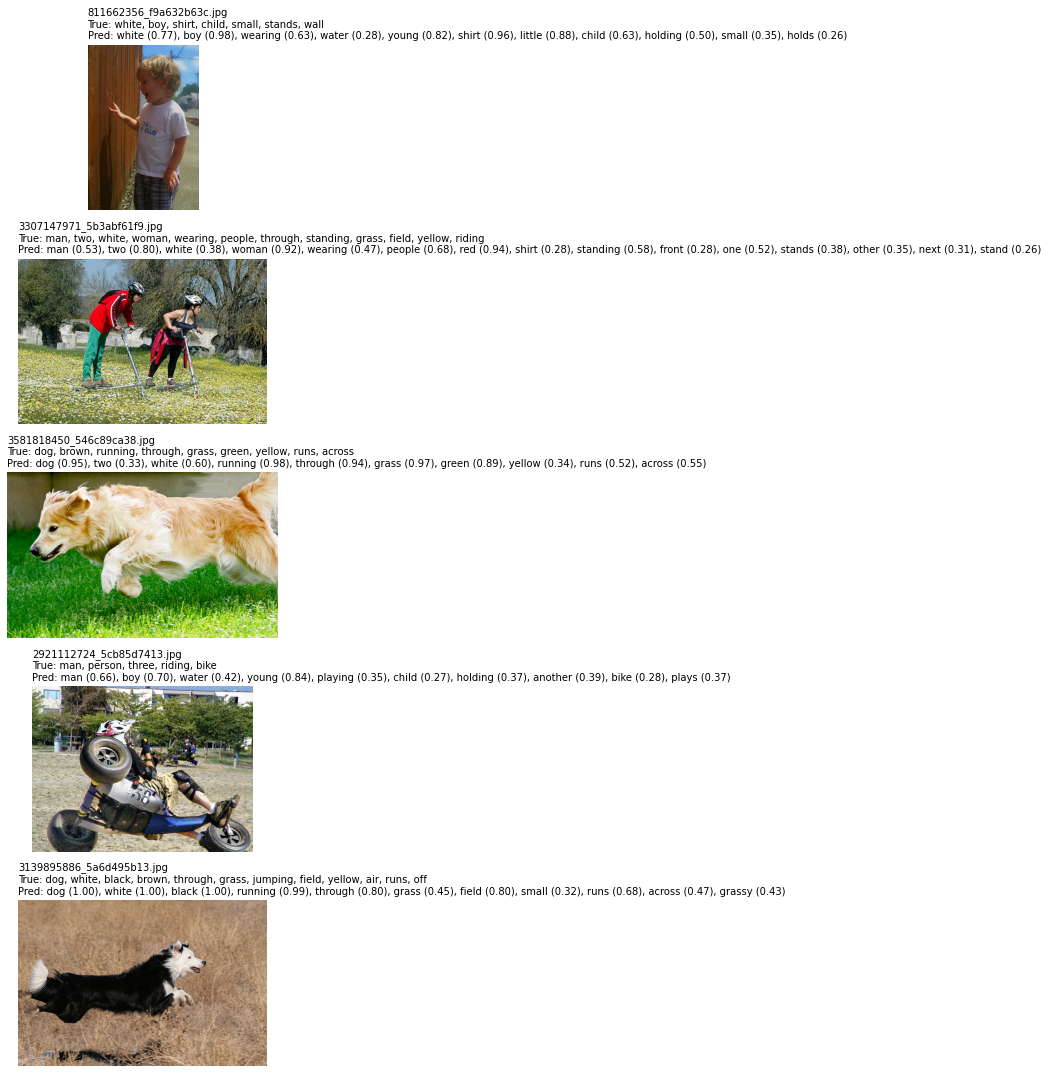

In [ ]:
# ==========================================
# 10. Example Predictions
# ==========================================
import matplotlib.pyplot as plt
import random

model.eval()

num_examples = 5
sample_ids = random.sample(test_df["image_id"].tolist(), num_examples)

plt.figure(figsize=(15, num_examples * 3))

# Same preprocessing as in training
transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225])
])

for i, img_id in enumerate(sample_ids):
    img_path = os.path.join("dataset/Images", img_id)
    image = Image.open(img_path).convert("RGB")
    input_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        preds_np = model(input_tensor).cpu().numpy()[0]

    # Binarize with the tuned threshold
    preds_bin = (preds_np > 0.25).astype(int)

    true_labels = [tokens[j] for j, val in enumerate(label_dict[img_id]) if val == 1]
    pred_labels = [
        f"{tokens[j]} ({preds_np[j]:.2f})"
        for j, val in enumerate(preds_bin) if val == 1
    ]

    plt.subplot(num_examples, 1, i + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(
        f"{img_id}\n"
        f"True: {', '.join(true_labels)}\n"
        f"Pred: {', '.join(pred_labels)}",
        fontsize=10,
        loc="left"
    )

plt.tight_layout()
plt.show()